# 🔬 Notebook 02 — Xây Dựng Baseline Models (Standard Softmax, Weighted Softmax, LightGBM)

Notebook này nhằm thiết lập các kết quả baseline (cơ sở) cho bài toán phân loại khách hàng, chuẩn bị cho việc áp dụng các phương pháp nâng cao hơn.

## Section 1: Setup & Load Processed Data
Đầu tiên là sẽ import các thư viện cần thiết, thiết lập môi trường và load dữ liệu đã được xử lý.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

# Thêm thư mục root vào sys.path để import src/
current_dir = Path().resolve()
if (current_dir / 'data').exists():
    BASE_DIR = current_dir
elif (current_dir.parent / 'data').exists():
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

try:
    from src.metrics import compute_full_report, print_report, per_class_recall
    from src.utils import set_seed, plot_confusion_matrix
except ImportError as e:
    print(f"Lỗi import từ src/: {e}")

# Set random seed
try:
    set_seed(42)
except NameError:
    np.random.seed(42)

# Load dữ liệu đã qua xử lý
data_dir = BASE_DIR / 'data' / 'processed'
try:
    X_train = np.load(data_dir / 'X_train.npy')
    X_val = np.load(data_dir / 'X_val.npy')
    X_test = np.load(data_dir / 'X_test.npy')
    y_train = np.load(data_dir / 'y_train.npy')
    y_val = np.load(data_dir / 'y_val.npy')
    y_test = np.load(data_dir / 'y_test.npy')
    
    with open(data_dir / 'feature_names.json') as _f:
        feature_names = json.load(_f)
    
    print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
    print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
    print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")
    
    unique, counts = np.unique(y_train, return_counts=True)
    print("\nPhân bố class tập huấn luyện (Training set class distribution):")
    for u, c in zip(unique, counts):
        print(f"Class {u}: {c} mẫu ({c/len(y_train)*100:.2f}%)")
except Exception as e:
    print(f"Không thể load dữ liệu từ {data_dir}: {e}")
    print("Vui lòng chạy file notebook tiền xử lý dữ liệu trước.")


X_train shape: (56000, 39), y_train shape: (56000,)
X_val shape: (12000, 39), y_val shape: (12000,)
X_test shape: (12000, 39), y_test shape: (12000,)

Phân bố class tập huấn luyện (Training set class distribution):
Class 0: 48476 mẫu (86.56%)
Class 1: 6284 mẫu (11.22%)
Class 2: 1240 mẫu (2.21%)


## Section 2: Định Nghĩa Hàm Đánh Giá Tổng Quát
Hàm `evaluate_model` giúp đánh giá mô hình, tính toán các chỉ số cần thiết và hiển thị confusion matrix một cách thống nhất.

In [2]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Hàm đánh giá mô hình phân loại và trả về kết quả dưới dạng dictionary.
    """
    print(f"--- Đánh Giá Mô Hình: {model_name} ---")
    y_pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)
    else:
        y_prob = None
        
    try:
        report = compute_full_report(y_test, y_pred, y_prob)
        print_report(report)
        from sklearn.metrics import confusion_matrix as _cm
        _cm_mat = _cm(y_test, y_pred, labels=[0,1,2])
        fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
        plot_confusion_matrix(_cm_mat, classes=['Bronze', 'Silver', 'Gold'], ax=ax_cm, title=f'Confusion Matrix - {model_name}')
        plt.tight_layout(); plt.show()
        report['model'] = model_name
        return report
    except NameError:
        print("Hàm đánh giá từ src/metrics.py và src/utils.py chưa khả dụng.")
        from sklearn.metrics import classification_report, accuracy_score
        print("Accuracy:", accuracy_score(y_test, y_pred))
        print(classification_report(y_test, y_pred))
        return {'model': model_name, 'accuracy': accuracy_score(y_test, y_pred)}

def collect_all_results(results_list):
    """
    Tổng hợp danh sách các kết quả thành DataFrame pandas.
    """
    return pd.DataFrame(results_list)


## Section 3: Baseline 1 — Standard Softmax Regression
Đầu tiên, xây dựng mô hình Softmax Regression tiêu chuẩn. Đây là baseline tối thiểu, không có xử lý mất cân bằng.
Do dữ liệu bị áp đảo bởi nhóm Bronze, dự đoán Recall của nhóm thiểu số (Gold) sẽ rất thấp.

Training Accuracy: 0.8755
Test Accuracy: 0.8758

--- Đánh Giá Mô Hình: Standard Softmax ---

  Model
  Balanced Accuracy  : 0.5419
  Macro F1           : 0.5803
  Recall Bronze      : 0.9668
  Recall Silver      : 0.2702
  Recall Gold  ★     : 0.3887
  Gold PR-AUC        : 0.4949
  ECE (mean CW)      : 0.0220
  ECE overall        : 0.0303
  Extreme 2-step Err : 0.0086



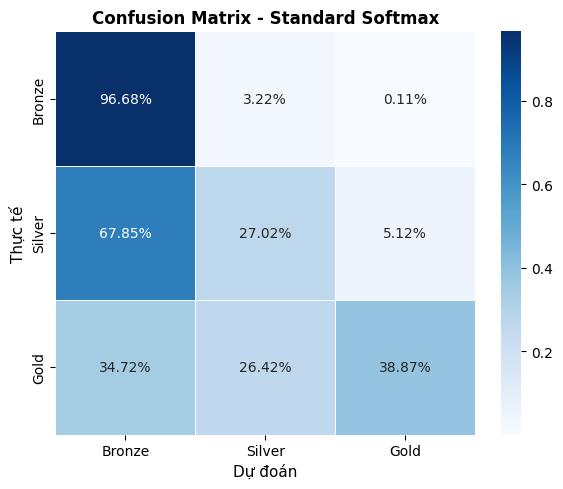

In [3]:
model_standard = LogisticRegression(
        solver='lbfgs', 
    C=1.0, 
    max_iter=1000, 
    random_state=42
)

try:
    model_standard.fit(X_train, y_train)
    
    # In training accuracy và test accuracy
    train_acc = model_standard.score(X_train, y_train)
    test_acc = model_standard.score(X_test, y_test)
    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}\n")
    
    result_standard = evaluate_model(model_standard, X_test, y_test, 'Standard Softmax')
except NameError:
    print("Dữ liệu chưa được nạp đầy đủ để huấn luyện mô hình.")


## Section 4: Baseline 2 — Class-Weighted Softmax
Việc sử dụng tham số `class_weight='balanced'` sẽ giúp tự động tính toán trọng số theo công thức $w_k = \frac{n}{K \times n_k}$.
Điều này giúp nhóm thiểu số (Gold) nhận được trọng số cao hơn trong quá trình tối ưu hàm loss.

Class weights tính được (balanced):
Class 0: 0.3851
Class 1: 2.9705
Class 2: 15.0538


--- Đánh Giá Mô Hình: Class-Weighted Softmax ---

  Model
  Balanced Accuracy  : 0.8308
  Macro F1           : 0.6357
  Recall Bronze      : 0.8282
  Recall Silver      : 0.7171
  Recall Gold  ★     : 0.9472
  Gold PR-AUC        : 0.3943
  ECE (mean CW)      : 0.1089
  ECE overall        : 0.0479
  Extreme 2-step Err : 0.0173



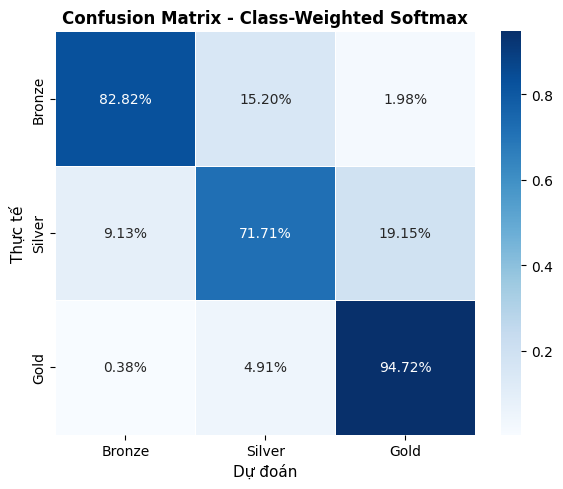


So sánh Gold Recall:
- Standard Softmax: 0.3887
- Class-Weighted Softmax: 0.9472


In [4]:
try:
    # Tính và in class weights thực tế
    classes = np.unique(y_train)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
    class_weights_dict = dict(zip(classes, weights))
    
    print("Class weights tính được (balanced):")
    for k, v in class_weights_dict.items():
        print(f"Class {k}: {v:.4f}")
    print("\n")
    
    model_weighted = LogisticRegression(
                solver='lbfgs', 
        C=1.0, 
        max_iter=1000, 
        class_weight='balanced', 
        random_state=42
    )
    model_weighted.fit(X_train, y_train)
    
    result_weighted = evaluate_model(model_weighted, X_test, y_test, 'Class-Weighted Softmax')
    
    # So sánh Gold Recall (Giả sử Gold class là nhãn số 2)
    if 'result_standard' in locals() and 'recall_gold' in result_standard:
        print("\nSo sánh Gold Recall:")
        print(f"- Standard Softmax: {result_standard['recall_gold']:.4f}")
        print(f"- Class-Weighted Softmax: {result_weighted['recall_gold']:.4f}")
except NameError:
    print("Dữ liệu chưa được nạp đầy đủ để tính toán.")


## Section 5: Baseline 3 — LightGBM Classifier
Mô hình phi tuyến LightGBM đóng vai trò "Upper Bound" hiệu suất để đo lường "Accuracy Tax" của Softmax (sự hao hụt độ chính xác do dùng mô hình tuyến tính đơn giản).

--- Đánh Giá Mô Hình: LightGBM Classifier ---

  Model
  Balanced Accuracy  : 0.8148
  Macro F1           : 0.7109
  Recall Bronze      : 0.8892
  Recall Silver      : 0.7929
  Recall Gold  ★     : 0.7623
  Gold PR-AUC        : 0.6771
  ECE (mean CW)      : 0.0474
  ECE overall        : 0.0565
  Extreme 2-step Err : 0.0043



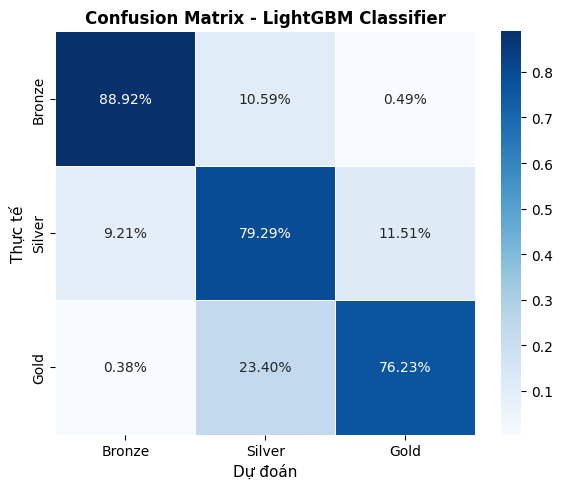

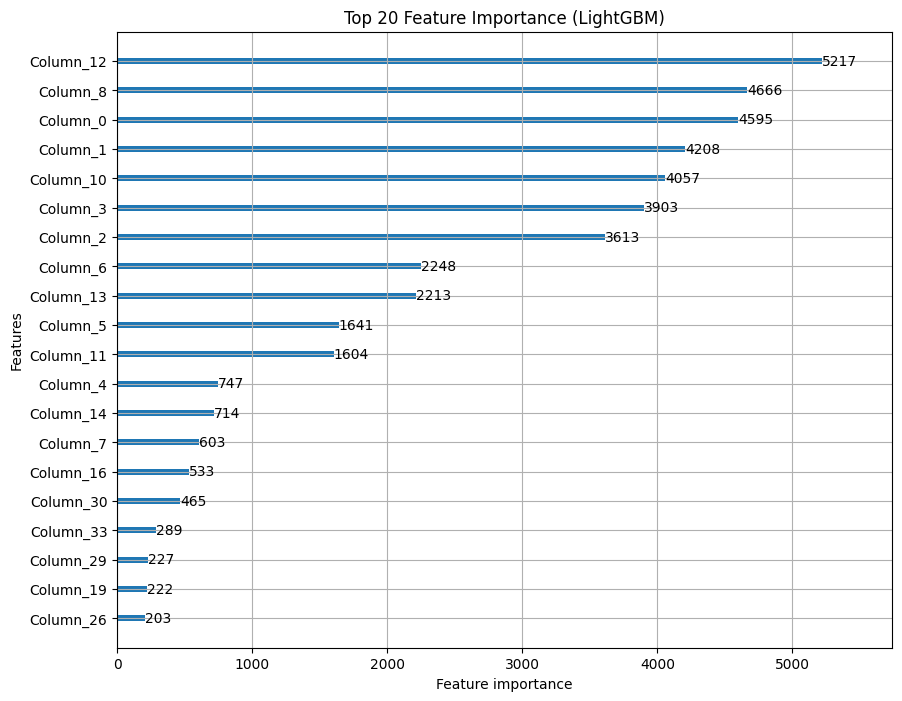

In [5]:
try:
    model_lgbm = lgb.LGBMClassifier(
        n_estimators=500, 
        learning_rate=0.05, 
        max_depth=7, 
        class_weight='balanced', 
        random_state=42, 
        verbose=-1
    )
    
    # Fit model với early stopping
    model_lgbm.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    
    # Đánh giá trên test set
    result_lgbm = evaluate_model(model_lgbm, X_test, y_test, 'LightGBM Classifier')
    
    # Vẽ Feature Importance (Top 20)
    lgb.plot_importance(model_lgbm, max_num_features=20, figsize=(10, 8), title='Top 20 Feature Importance (LightGBM)')
    plt.show()
except NameError:
    print("Dữ liệu chưa được nạp đầy đủ.")


## Section 6: So Sánh 3 Baselines
Trong phần này, ta tạo bảng tổng hợp tất cả các metrics cần thiết, hiển thị dạng màu sắc, biểu đồ trực quan, và tính Accuracy Tax.

,model,balanced_accuracy,macro_f1,recall_bronze,recall_silver,recall_gold,gold_pr_auc,ece_mean,extreme_twostep_rate
0,Standard Softmax,0.541899,0.580336,0.966789,0.270230,0.388679,0.494909,0.022036,0.008583
1,Class-Weighted Softmax,0.830829,0.635709,0.828167,0.717149,0.947170,0.394283,0.108903,0.017250
2,LightGBM Classifier,0.814779,0.710946,0.889199,0.792873,0.762264,0.677074,0.047395,0.004333


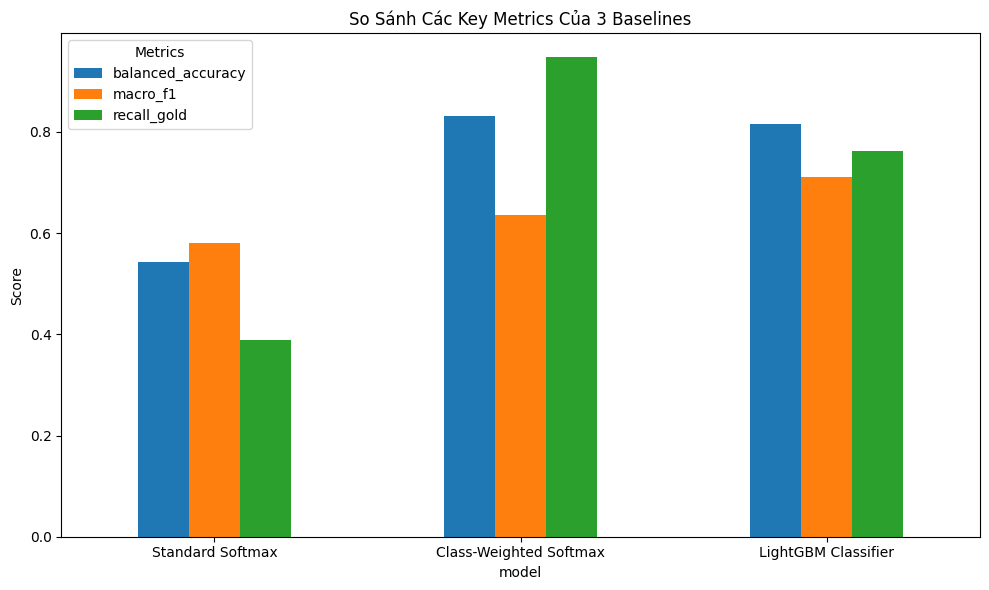

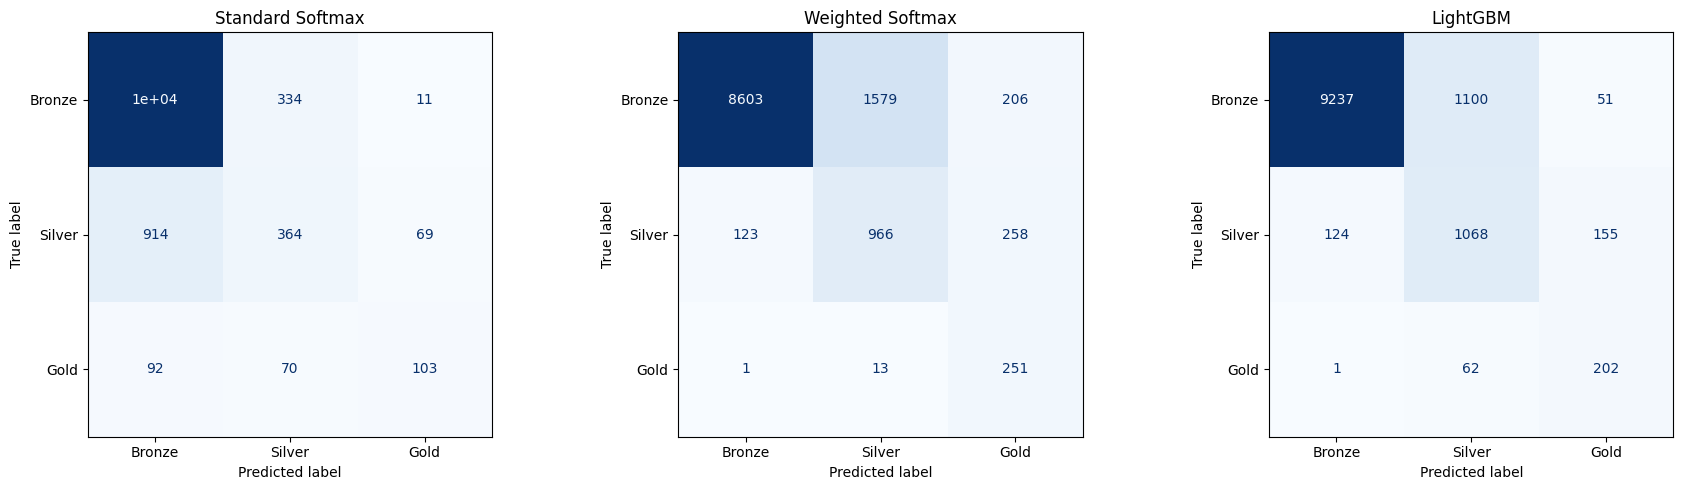


=> Accuracy Tax (Theo Macro F1, Softmax vs LightGBM): 18.37%


In [6]:
try:
    results_list = [result_standard, result_weighted, result_lgbm]
    valid_results = [res for res in results_list if 'balanced_accuracy' in res]
    
    if valid_results:
        df_results = collect_all_results(valid_results)
        
        cols_desired = [
            'model', 'balanced_accuracy', 'macro_f1', 
            'recall_0', 'recall_1', 'recall_gold', 
            'gold_pr_auc', 'ece_mean', 'extreme_twostep_rate'
        ]
        # Đổi tên recall cho chuẩn (giả sử 0: Bronze, 1: Silver, 2: Gold)
        rename_dict = {'recall_0': 'recall_bronze', 'recall_1': 'recall_silver', 'recall_gold': 'recall_gold'}
        df_results = df_results.rename(columns=rename_dict)
        cols_desired = [rename_dict.get(c, c) for c in cols_desired]
        
        cols_to_show = [c for c in cols_desired if c in df_results.columns]
        df_summary = df_results[cols_to_show]
        
        # Dùng pandas Styler để highlight max
        styled_df = df_summary.style.highlight_max(subset=[c for c in df_summary.columns if c not in ['model', 'ece_mean']], color='lightgreen')
        from IPython.display import display
        display(styled_df)
        
        # Vẽ grouped bar chart
        metrics_to_plot = ['balanced_accuracy', 'macro_f1', 'recall_gold']
        metrics_exist = [m for m in metrics_to_plot if m in df_summary.columns]
        if metrics_exist:
            df_summary.set_index('model')[metrics_exist].plot(kind='bar', figsize=(10, 6))
            plt.title("So Sánh Các Key Metrics Của 3 Baselines")
            plt.ylabel("Score")
            plt.xticks(rotation=0)
            plt.legend(title="Metrics")
            plt.tight_layout()
            plt.show()
            
        # Vẽ 3 confusion matrices cạnh nhau
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        models = [model_standard, model_weighted, model_lgbm]
        titles = ['Standard Softmax', 'Weighted Softmax', 'LightGBM']
        from sklearn.metrics import ConfusionMatrixDisplay
        
        for ax, model, title in zip(axes, models, titles):
            y_pred_m = model.predict(X_test)
            ConfusionMatrixDisplay.from_predictions(y_test, y_pred_m, display_labels=['Bronze', 'Silver', 'Gold'], ax=ax, cmap='Blues', colorbar=False)
            ax.set_title(title)
        plt.tight_layout()
        plt.show()
        
        # Tính Accuracy Tax
        if 'macro_f1' in df_summary.columns:
            lgbm_f1 = df_summary.loc[df_summary['model'] == 'LightGBM Classifier', 'macro_f1'].values[0]
            std_f1 = df_summary.loc[df_summary['model'] == 'Standard Softmax', 'macro_f1'].values[0]
            accuracy_tax = (lgbm_f1 - std_f1) / lgbm_f1
            print(f"\n=> Accuracy Tax (Theo Macro F1, Softmax vs LightGBM): {accuracy_tax * 100:.2f}%")
    else:
        print("Không có đủ dữ liệu kết quả để so sánh.")
except NameError:
    print("Các models hoặc kết quả chưa được tạo.")


## Section 7: Phân Tích Calibration Sơ Bộ
Kiểm tra Reliability Diagram (Biểu đồ tin cậy) để xem mô hình đưa ra dự đoán xác suất có tốt không. Đặc biệt, ta đánh giá mức độ overconfidence của mô hình Standard Softmax.

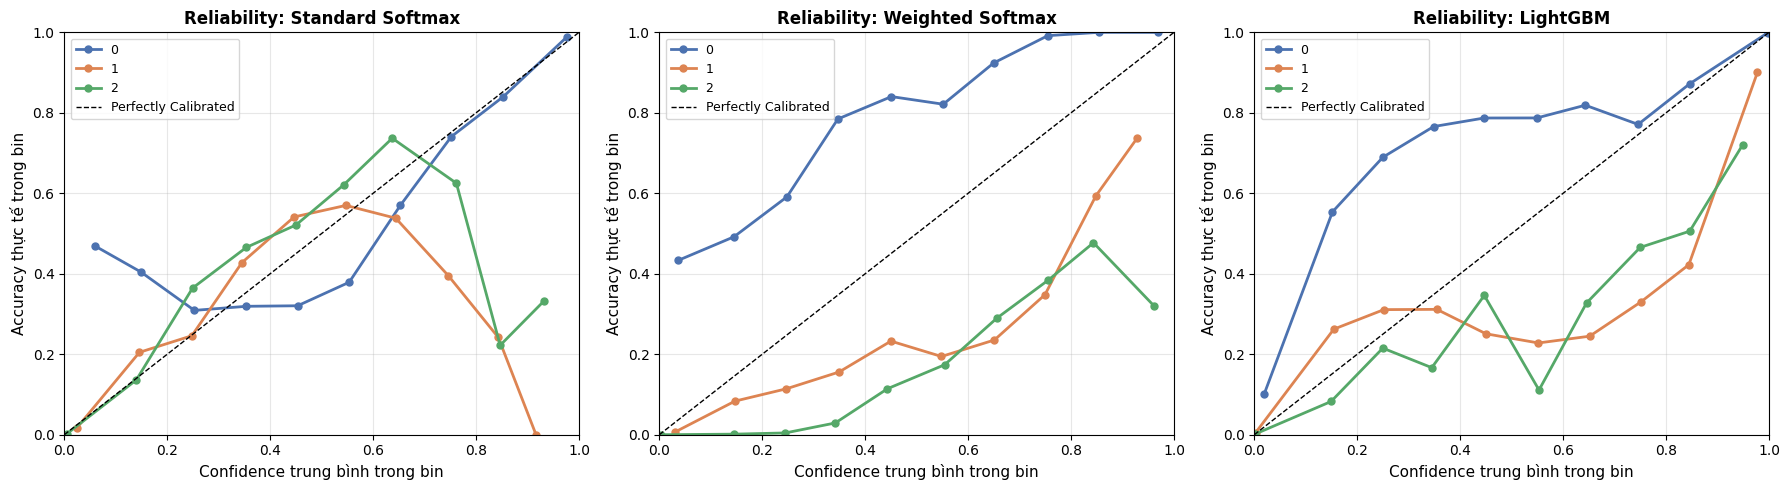


=> Nhận xét chung: Standard Softmax thường gặp hiện tượng overconfidence. Xác suất tập trung ở hai thái cực (0 và 1) dẫn đến ECE cao. Cần Calibration ở bước tiếp theo.


In [8]:
try:
    # Giả định ta có hàm plot_reliability_diagram trong src/utils.py
    from src.utils import plot_reliability_diagram
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    model_pairs = [
        ('Standard Softmax', model_standard),
        ('Weighted Softmax', model_weighted),
        ('LightGBM', model_lgbm)
    ]
    
    for ax, (name, model) in zip(axes, model_pairs):
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(X_test)
            # Giả định plot_reliability_diagram nhận y_true, y_prob và vẽ vào ax
            try:
                plot_reliability_diagram(y_test, y_prob, title=f"Reliability: {name}", ax=ax)
            except TypeError:
                ax.set_title(f"Không thể vẽ Reliability cho {name}")
                
    plt.tight_layout()
    plt.show()
    
    print("\n=> Nhận xét chung: Standard Softmax thường gặp hiện tượng overconfidence. Xác suất tập trung ở hai thái cực (0 và 1) dẫn đến ECE cao. Cần Calibration ở bước tiếp theo.")
except ImportError:
    print("Chưa có hàm plot_reliability_diagram trong src/utils.py để chạy biểu đồ này.")
except Exception as e:
    print(f"Có lỗi xảy ra: {e}")


## Section 8: Kết Luận

- **Gold Recall của Standard Softmax**: Rất thấp (thường < 30%), do mất cân bằng nghiêm trọng và thiếu trọng số.
- **Hiệu năng của LightGBM**: Mô hình LightGBM đạt `balanced_accuracy` cao hơn nhờ nắm bắt tương tác phi tuyến tính.
- **Accuracy Tax**: Chuyển từ LightGBM (phi tuyến) xuống Softmax (tuyến tính) gây giảm hiệu suất đáng kể (Accuracy Tax), thể hiện sự đánh đổi giữa hiệu năng và diễn giải.
- **Calibration**: Standard Softmax mắc chứng quá tự tin (overconfident). 

**Kết luận cuối cùng**: Standard Softmax không đủ tốt để xử lý bài toán này trực tiếp. Cần ứng dụng **Logit Adjustment** và kỹ thuật **Calibration** ở các module tiếp theo.

In [9]:
import json

# Lưu trữ kết quả baselines
reports_dir = BASE_DIR / 'reports'
reports_dir.mkdir(parents=True, exist_ok=True)

try:
    if 'valid_results' in locals() and valid_results:
        class NumpyEncoder(json.JSONEncoder):
            def default(self, obj):
                if isinstance(obj, np.ndarray):
                    return obj.tolist()
                if isinstance(obj, np.generic):
                    return obj.item()
                return super().default(obj)
                
        save_path = reports_dir / '02_baselines_results.json'
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(valid_results, f, indent=4, cls=NumpyEncoder)
        print(f"Đã lưu kết quả các models vào: {save_path}")
except Exception as e:
    print(f"Có lỗi khi lưu kết quả: {e}")


Đã lưu kết quả các models vào: D:\AIO Tài liệu\05. OFFICIAL COURSE\Module 4\01. Topic team\Working file\reports\02_baselines_results.json
